In [122]:
!pip install torch==1.13.1+cpu torchvision==0.14.1+cpu torchaudio==0.13.1+cpu -f https://download.pytorch.org/whl/torch_stable.html

Looking in links: https://download.pytorch.org/whl/torch_stable.html


In [123]:
!pip install pandas numpy scikit-learn matplotlib

In [124]:
!pip install torcheval

In [125]:
!python --version

Python 3.8.20


In [126]:
import sys
print(sys.executable)

D:\app\envs\ds68\python.exe


# Prepare the data

In [2]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [3]:
import pandas as pd
import numpy as np
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn import preprocessing

In [4]:
# Read data
data = pd.read_csv('abalony.csv', index_col=0)

In [5]:
# Explore data
print(data.head())

   Sex  Length  Diameter  Height  Whole weight  Whole weight.1  \
id                                                               
0    F   0.550     0.430   0.150        0.7715          0.3285   
1    F   0.630     0.490   0.145        1.1300          0.4580   
2    I   0.160     0.110   0.025        0.0210          0.0055   
3    M   0.595     0.475   0.150        0.9145          0.3755   
4    I   0.555     0.425   0.130        0.7820          0.3695   

    Whole weight.2  Shell weight  Rings  
id                                       
0           0.1465        0.2400     11  
1           0.2765        0.3200     11  
2           0.0030        0.0050      6  
3           0.2055        0.2500     10  
4           0.1600        0.1975      9  


In [6]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
Index: 29192 entries, 0 to 29191
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             29192 non-null  object 
 1   Length          29192 non-null  float64
 2   Diameter        29192 non-null  float64
 3   Height          29192 non-null  float64
 4   Whole weight    29192 non-null  float64
 5   Whole weight.1  29192 non-null  float64
 6   Whole weight.2  29192 non-null  float64
 7   Shell weight    29192 non-null  float64
 8   Rings           29192 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 2.2+ MB
None


In [7]:
print(data.shape)

(29192, 9)


In [8]:
# check missing values
data.isnull().sum()

Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Whole weight.1    0
Whole weight.2    0
Shell weight      0
Rings             0
dtype: int64

In [9]:
# check duplicate data
data.duplicated().sum()

0

In [10]:
# Clean data and create dummy
data = pd.read_csv('abalony.csv',index_col=0)
hot=pd.get_dummies(data['Sex'],dtype=int)
data=pd.concat([data,hot],axis=1) # เอา column ใหม่ไปต่อกับ dataframe
data=data.drop(['Sex'],axis=1) # ลบ column Sex
col = data.pop('Rings') # pop rings ออก เก็บใส่ตัวแปร col 
data['Rings'] = col # ใส่ Rings กลับเข้าไป เพื่อให้อยู่ column สุดท้าย
data.head()

,Length,Diameter,Height,Whole weight,Whole weight.1,Whole weight.2,Shell weight,F,I,M,Rings
id,,,,,,,,,,,
0,0.550,0.430,0.150,0.7715,0.3285,0.1465,0.2400,1,0,0,11
1,0.630,0.490,0.145,1.1300,0.4580,0.2765,0.3200,1,0,0,11
2,0.160,0.110,0.025,0.0210,0.0055,0.0030,0.0050,0,1,0,6
3,0.595,0.475,0.150,0.9145,0.3755,0.2055,0.2500,0,0,1,10
4,0.555,0.425,0.130,0.7820,0.3695,0.1600,0.1975,0,1,0,9


In [11]:
# นับจำนวนค่าที่ไม่ซ้ำในแต่ละ column ของ DataFrame
data.nunique()

Length             148
Diameter           115
Height              64
Whole weight      2778
Whole weight.1    1620
Whole weight.2     904
Shell weight      1007
F                    2
I                    2
M                    2
Rings               28
dtype: int64

In [12]:
print(data.corr()['Rings'].sort_values(ascending=False)) 
# check ว่า แต่ละ feature สัมพันธ์กับ Rings มากแค่ไหน

Rings             1.000000
Shell weight      0.695804
Height            0.664746
Diameter          0.634326
Length            0.620888
Whole weight      0.617406
Whole weight.2    0.587589
Whole weight.1    0.515203
F                 0.303501
M                 0.235812
I                -0.517350
Name: Rings, dtype: float64


In [13]:
# Set input(X) and output(y)
X = data.iloc[:, 0:-1]  # เอาทุก rows ของ columns ตั้งแต่ 0 ถึง ก่อน column สุดท้าย
y = data.iloc[:, -1]  # เอาทุก rows ของ columns สุดท้าย
print(X.head())
print(y.head())

    Length  Diameter  Height  Whole weight  Whole weight.1  Whole weight.2  \
id                                                                           
0    0.550     0.430   0.150        0.7715          0.3285          0.1465   
1    0.630     0.490   0.145        1.1300          0.4580          0.2765   
2    0.160     0.110   0.025        0.0210          0.0055          0.0030   
3    0.595     0.475   0.150        0.9145          0.3755          0.2055   
4    0.555     0.425   0.130        0.7820          0.3695          0.1600   

    Shell weight  F  I  M  
id                         
0         0.2400  1  0  0  
1         0.3200  1  0  0  
2         0.0050  0  1  0  
3         0.2500  0  0  1  
4         0.1975  0  1  0  
id
0    11
1    11
2     6
3    10
4     9
Name: Rings, dtype: int64


In [14]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 99)
# Scaling
scaler = preprocessing.StandardScaler() # mean = 0 , std = 1
scaler.fit(X_train) 
X_tr = scaler.transform(X_train)
X_te = scaler.transform(X_test)
print('X_train size\n' , X_train.shape) 
print('y_train size\n ', y_train.shape)

X_train size
 (23353, 10)
y_train size
  (23353,)


In [15]:
# Convert to Tensors
X_tr = torch.tensor(X_tr, dtype=torch.float32)
y_tr = torch.tensor(np.array(y_train), dtype=torch.float32).reshape(-1,1)
X_te = torch.tensor(X_te, dtype=torch.float32)
y_te = torch.tensor(np.array(y_test), dtype=torch.float32).reshape(-1,1)
print('X_train\n' , X_tr.shape) 
print('y_train\n ', y_tr.shape)
print('X_test\n' , X_te.shape) 
print('y_test\n ', y_te.shape)

X_train
 torch.Size([23353, 10])
y_train
  torch.Size([23353, 1])
X_test
 torch.Size([5839, 10])
y_test
  torch.Size([5839, 1])


In [16]:
# Create DataLoader
bs = 64 # batch size
trainloader = DataLoader(list(zip(X_tr, y_tr)), shuffle=True, batch_size=bs) 
testloader = DataLoader(list(zip(X_te, y_te)), shuffle=False, batch_size=bs)

# Define the Model

In [142]:
class Model2(nn.Module):
    def __init__(self, input_size, hidsize1, hidsize2, hidsize3, output_size):
        super(Model2, self).__init__()
        # Layer1
        self.fc1 = nn.Linear(input_size, hidsize1) 
        self.relu1 = nn.ReLU()
        # Layer2
        self.fc2 = nn.Linear(hidsize1, hidsize2) 
        self.relu2 = nn.ReLU()
        # Layer 3
        self.fc3 = nn.Linear(hidsize2, hidsize3)
        self.relu3 = nn.ReLU()
        # output layer
        self.fc4 = nn.Linear(hidsize3, output_size) 
    
    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.relu3(self.fc3(x))
        x = self.fc4(x)
        return x


In [143]:
# Set parameters
input_size = X_train.shape[1]  # จำนวน input feature
hidsize1 = 32  # จำนวน neuron ใน hidden layer 1
hidsize2 = 16  # จำนวน neuron ใน hidden layer 2
hidsize3 = 8  # จำนวน neuron ใน hidden layer 2
output_size = 1 # output
# Define model
model = Model2(input_size, hidsize1, hidsize2, hidsize3, output_size)

# Train the Model

In [144]:
criterion = nn.MSELoss() # ระบุ loss function ที่ใช้สำหรับ Regression
lr = 0.001 # learning rate (α) ควรเล็ก *เล็กไปช้า *ใหญ่ไปอาจ diverse
epochs  = 100 # รอบของการฝึกทุก instance
optimizer = optim.SGD(model.parameters(), lr=lr) 
# SGD ชื่อ Algorithm ที่ปรับ weight ให้, Ir=Ir คือ ปรับด้วยความถี่เท่าไหร่

In [145]:
train_losses = [] # เอาไว้เก็บค่า losses สะสมของทุก batch ที่นำไปหาค่าเฉลี่ยแล้ว
test_losses = []

for epoch in range(epochs): # loop ทีละ 1 epoch
    tr_ep_loss = 0 # เก็บค่า losses รวม สะสมของทุก batch
    te_ep_loss = 0
    
    model.train() # เพิ่มโหมด trainnnnnnnnnnnnn
    for inputs, outputs in trainloader: # ใช้ trainloader ที่แบ่ง batch ให้เรา loop ทีละ batch
        # Forward pass 
        y_pred = model(inputs)
        # Calculate loss 
        loss = criterion(y_pred, outputs)
        tr_ep_loss += loss
        # Backward pass and optimization
        optimizer.zero_grad() # ทำให้ลืมค่าที่ทำรอบก่อนหน้าไป
        loss.backward() # ให้มันดูว่ามี parameter ตัวไหนบ้างที่ต้องปรับค่า
        optimizer.step() # ต้องปรับเท่าไหร่ ปรับ weight ทุกตัวในโมเดล
        # Testing 
    model.eval()
    with torch.no_grad():
        for inputs_te, outputs_te in testloader:
            y_pred_test = model(inputs_te)
            loss_test = criterion(y_pred_test, outputs_te)
            te_ep_loss += loss_test
            
    tr_ep_loss = tr_ep_loss.item()/len(X_train) # หาค่าเฉลี่ยของ training loss
    train_losses.append(tr_ep_loss) # append ค่า loss ที่เฉลี่ยแล้ว ไปเก็บ
    te_ep_loss = te_ep_loss.item()/len(X_test) # หาค่าเฉลี่ยของ testing loss
    test_losses.append(te_ep_loss) # append ค่า loss ที่เฉลี่ยแล้ว ไปเก็บ
    
    if (epoch+1) % 10 == 0 or epoch == 0:
        print(f'Epoch {epoch+1} / {epochs} Train Loss: {tr_ep_loss:.6f} Test Loss: {te_ep_loss:.6f}') 

Epoch 1 / 100 Train Loss: 0.300831 Test Loss: 0.091499
Epoch 10 / 100 Train Loss: 0.076273 Test Loss: 0.070101
Epoch 20 / 100 Train Loss: 0.063103 Test Loss: 0.060336
Epoch 30 / 100 Train Loss: 0.060954 Test Loss: 0.059200
Epoch 40 / 100 Train Loss: 0.060710 Test Loss: 0.058114
Epoch 50 / 100 Train Loss: 0.060017 Test Loss: 0.058689
Epoch 60 / 100 Train Loss: 0.059823 Test Loss: 0.058265
Epoch 70 / 100 Train Loss: 0.059479 Test Loss: 0.057150
Epoch 80 / 100 Train Loss: 0.059433 Test Loss: 0.057845
Epoch 90 / 100 Train Loss: 0.059244 Test Loss: 0.057151
Epoch 100 / 100 Train Loss: 0.059068 Test Loss: 0.056907


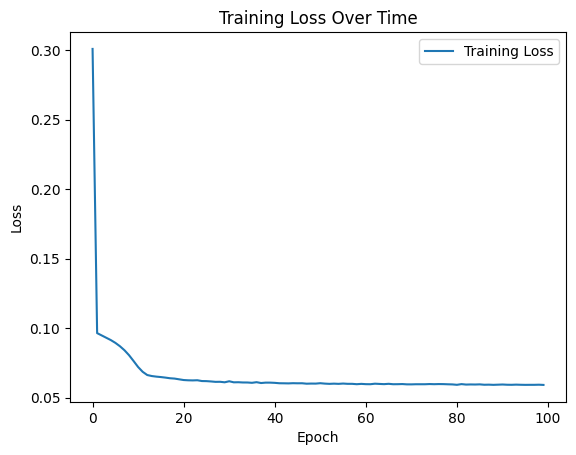

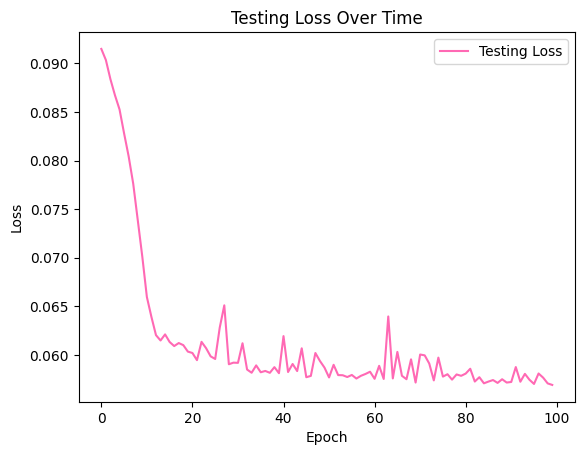

In [146]:
# Plot Training Loss
plt.plot(train_losses, label='Training Loss')
plt.title('Training Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show() 

# Plot Testing Loss
plt.plot(test_losses, label='Testing Loss', color='HotPink')
plt.title('Testing Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Evaluate the model + Make predictions

In [147]:
import torch
from torcheval.metrics import MeanSquaredError

metric = MeanSquaredError()

model.eval() # Fix parameter ช่วยให้ไม่ปรับค่า
with torch.no_grad():
    
    # Training Performance
    tr_y_pred = model(X_tr)
    tr_y = torch.reshape(y_tr, (-1, 1))
    metric.update(tr_y_pred, tr_y)
    print('Training Performance:', metric.compute().item()/len(X_train))
    
    # Testing Performance
    te_y_pred = model(X_te)
    te_y = torch.reshape(y_te, (-1, 1))
    metric.update(te_y_pred, te_y)
    print('Testing Performance:', metric.compute().item()/len(X_train))


Training Performance: 0.00015938072211123816
Testing Performance: 0.00015820397384487393
